# SMARTPHONE DATA ANALYSIS AND PREPROCESSING PROJECT
**Standardized Pipeline: Exploratory Data Analysis (EDA) -> Dataset Splitting (Train/Val/Test) -> Preprocessing & Feature Extraction**

### Import Libraries and Configure Plot Display

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Configure plot display settings
%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True

### Load Dataset into a Pandas DataFrame
Supports both Google Colab and local Jupyter Notebook environments.

In [2]:
file_path = 'phone_dataset_cleaned.csv'

# Check if running on Google Colab and allow file upload if not found locally
if not os.path.exists(file_path):
    try:
        from google.colab import files
        print("Running on Google Colab. Please select a file to upload:")
        uploaded = files.upload()
        file_path = list(uploaded.keys())[0]
    except ImportError:
        # Fallback path on the local machine
        file_path = r'D:\File Code\Smartphone Price Prediction\phone_dataset_cleaned.csv'

df_raw = pd.read_csv(file_path)
df = df_raw.copy()
print(f"Successfully loaded dataset: {df.shape[0]} rows and {df.shape[1]} columns.")
display(df.head())

Successfully loaded dataset: 1910 rows and 21 columns.


,Brand,Price (EUR),RAM (GB),ROM (GB),Screen Size (inch),Screen-to-Body Ratio (%),Display Panel,Rear Camera (MP),Front Camera (MP),Battery Capacity (mAh),...,Thickness (mm),Weight (g),Fingerprint Sensor,Network Support,Chip Brand,CPU Cores,CPU Clock Speed (GHz),Release Year,NFC_Clean,Diagonal Resolution (Pixels)
0,Acer,170.0,2.0,32.0,7.0,69.8,IPS LCD,13.0,2.0,3400.0,...,9.4,260.0,No,4G / LTE,MediaTek,4.0,1.30,2016.0,0,1468.60478
1,Acer,250.0,3.0,32.0,5.5,71.7,IPS LCD,13.0,5.0,4080.0,...,8.5,169.0,Available,4G / LTE,MediaTek,8.0,1.30,2016.0,0,2202.90717
2,Acer,120.0,1.0,8.0,5.0,NaN,IPS LCD,8.0,2.0,2000.0,...,NaN,NaN,No,4G / LTE,MediaTek,4.0,1.25,2016.0,0,1468.60478
3,Acer,230.0,3.0,32.0,5.5,69.0,IPS LCD,13.0,13.0,4020.0,...,8.5,166.0,No,4G / LTE,MediaTek,8.0,1.30,2015.0,0,1468.60478
4,Acer,200.0,2.0,16.0,5.5,70.3,IPS LCD,13.0,5.0,5000.0,...,10.0,NaN,No,4G / LTE,MediaTek,4.0,1.30,2016.0,0,1468.60478


## PART I: EXPLORATORY DATA ANALYSIS AND VISUALIZATION (EDA)
In this section, we examine the overall structure of the dataset, analyze missing values, inspect feature distributions, and explore the relationships between technical specifications and smartphone prices to uncover actionable insights.

### 1. Basic Information Analysis (Preliminary EDA)
We examine the overall structure of the dataset, including the number of rows, columns, data types, and missing (null) value counts.

In [3]:
print("--- Dataset Structure Information ---")
df.info()

print("\n--- Descriptive Statistics (Numeric) ---")
display(df.describe())

print("\n--- Missing Value Counts ---")
missing_counts = df.isnull().sum()
display(missing_counts[missing_counts > 0])

--- Dataset Structure Information ---
<class 'pandas.DataFrame'>
RangeIndex: 1910 entries, 0 to 1909
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Brand                         1910 non-null   str    
 1   Price (EUR)                   1910 non-null   float64
 2   RAM (GB)                      1792 non-null   float64
 3   ROM (GB)                      1838 non-null   float64
 4   Screen Size (inch)            1905 non-null   float64
 5   Screen-to-Body Ratio (%)      1832 non-null   float64
 6   Display Panel                 1762 non-null   str    
 7   Rear Camera (MP)              1908 non-null   float64
 8   Front Camera (MP)             1861 non-null   float64
 9   Battery Capacity (mAh)        1872 non-null   float64
 10  Battery Design                1910 non-null   str    
 11  Thickness (mm)                1824 non-null   float64
 12  Weight (g)                    1690 

,Price (EUR),RAM (GB),ROM (GB),Screen Size (inch),Screen-to-Body Ratio (%),Rear Camera (MP),Front Camera (MP),Battery Capacity (mAh),Thickness (mm),Weight (g),CPU Cores,CPU Clock Speed (GHz),Release Year,NFC_Clean,Diagonal Resolution (Pixels)
count,1910.000000,1792.000000,1838.000000,1905.000000,1832.000000,1908.000000,1861.000000,1872.000000,1824.000000,1690.000000,1885.000000,1877.000000,1909.000000,1910.000000,1905.000000
mean,232.712042,1.845982,22.395158,5.041349,66.464902,9.963077,3.775819,2562.146902,9.069298,157.958047,4.597878,1.488535,2014.257203,0.325654,1567.227069
std,136.686738,1.054884,27.027405,0.769781,6.529763,4.431226,3.403404,801.568976,1.689658,44.248241,2.271534,0.397166,1.643983,0.468742,571.973137
min,40.000000,1.000000,1.000000,3.000000,22.800000,0.300000,0.000000,1000.000000,4.900000,88.200000,1.000000,0.260000,2007.000000,0.000000,400.000000
25%,140.000000,1.000000,8.000000,4.500000,63.675000,8.000000,1.300000,2000.000000,7.900000,135.000000,4.000000,1.200000,2013.000000,0.000000,1101.453585
50%,200.000000,1.500000,16.000000,5.000000,67.400000,8.000000,2.000000,2460.000000,8.900000,149.000000,4.000000,1.400000,2014.000000,0.000000,1468.604780
75%,280.000000,2.000000,32.000000,5.500000,70.800000,13.000000,5.000000,3000.000000,9.900000,167.000000,8.000000,1.700000,2016.000000,1.000000,2202.907170
max,1400.000000,8.000000,256.000000,8.000000,93.200000,41.000000,20.000000,7000.000000,21.100000,480.000000,10.000000,2.700000,2017.000000,1.000000,4405.814340



--- Missing Value Counts ---


RAM (GB)                        118
ROM (GB)                         72
Screen Size (inch)                5
Screen-to-Body Ratio (%)         78
Display Panel                   148
Rear Camera (MP)                  2
Front Camera (MP)                49
Battery Capacity (mAh)           38
Thickness (mm)                   86
Weight (g)                      220
Chip Brand                      226
CPU Cores                        25
CPU Clock Speed (GHz)            33
Release Year                      1
Diagonal Resolution (Pixels)      5
dtype: int64

### 2. Visualizing Distributions of Columns with Missing Values
We plot distributions to inspect the characteristics of features containing missing values:
- **Distribution plots (Histogram/KDE)** for numeric features with missing values.
- **Count plots (Countplot)** for categorical features with missing values: `Display Panel`, `Chip Brand`.

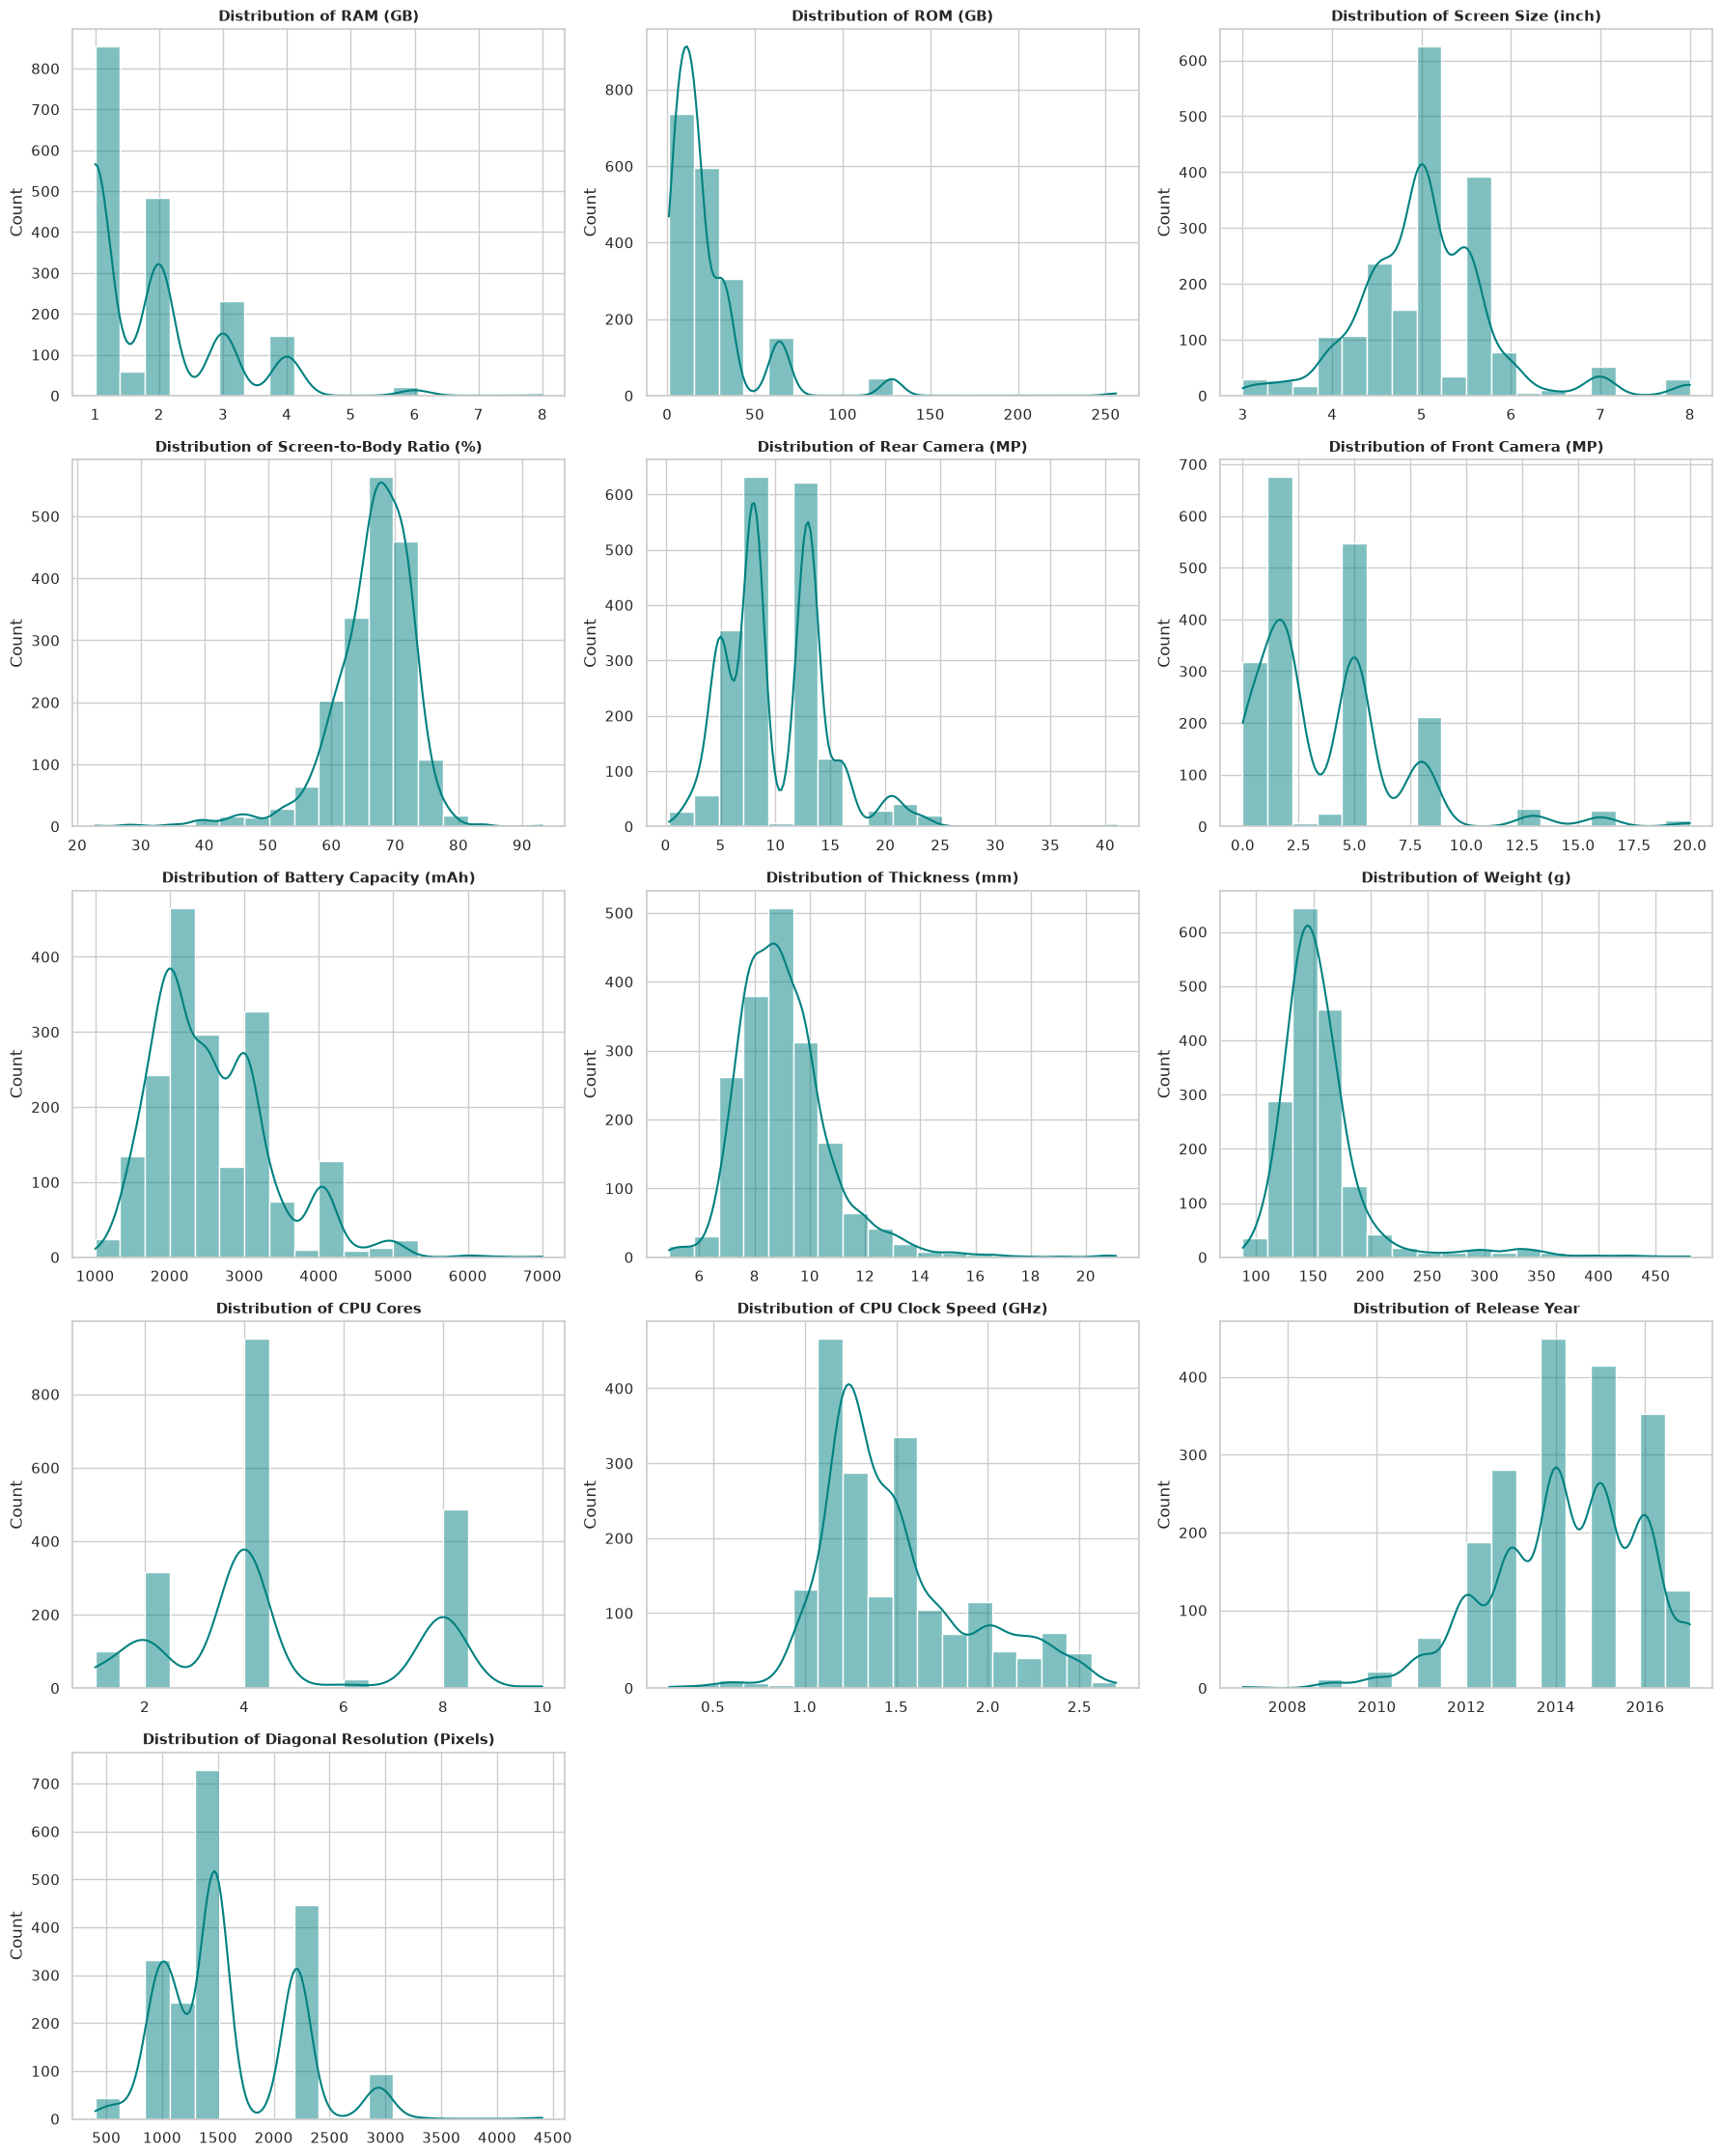

In [4]:
# 1. Plot distributions for numeric columns with missing values
numeric_cols_with_nan = [
    col for col in df.select_dtypes(include=[np.number]).columns
    if df[col].isnull().sum() > 0
]

n_cols = 3
n_rows = int(np.ceil(len(numeric_cols_with_nan) / n_cols))
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(18, 4.5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(numeric_cols_with_nan):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i], color='teal', bins=18)
    axes[i].set_title(f'Distribution of {col}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')

for j in range(len(numeric_cols_with_nan), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

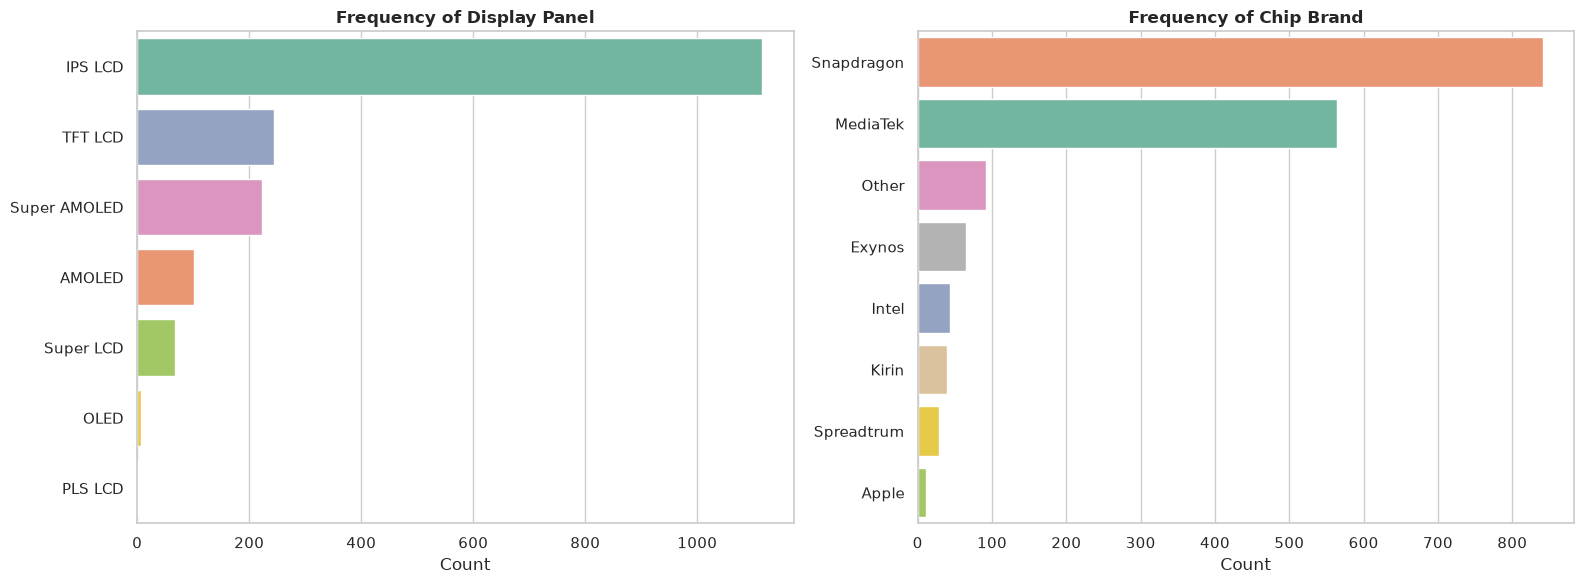

In [5]:
# 2. Plot distributions for categorical columns with missing values
categorical_cols_with_nan = [
    'Display Panel',
    'Chip Brand'
]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

for i, col in enumerate(categorical_cols_with_nan):
    order = df[col].value_counts().index
    sns.countplot(
        data=df,
        y=col,
        ax=axes[i],
        order=order,
        palette='Set2',
        hue=col,
        legend=False
    )
    axes[i].set_title(f'Frequency of {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Count')
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

### 3. Target Variable Distribution Analysis (`Price (EUR)`)
Next, we plot the price distribution to check its skewness and evaluate the effect of applying a logarithmic transformation (`log-transform`).

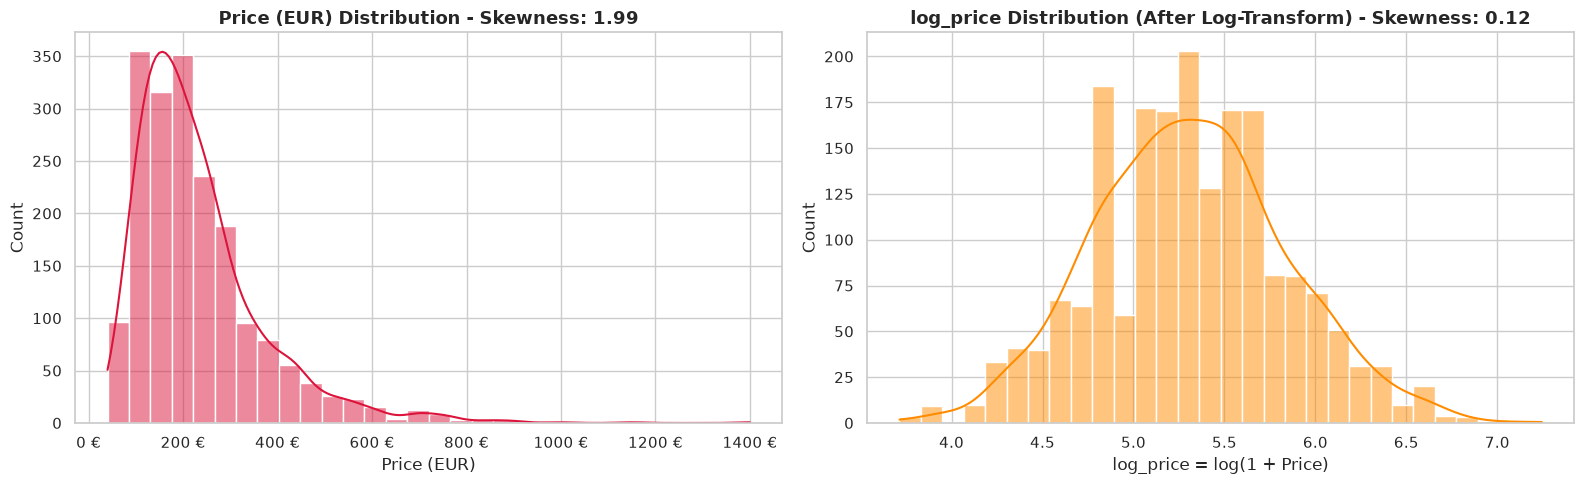

Initial Price (EUR) skewness: 1.99 (Heavily right-skewed due to concentration of budget/mid-range phones and fewer flagship models)
Skewness after log-transform: 0.12 (Much more symmetric and closer to a normal distribution)


In [6]:
from matplotlib.ticker import FuncFormatter

# Check original price distribution vs. log-transformed distribution
log_price_eda = np.log1p(df['Price (EUR)'])
price_skew = df['Price (EUR)'].skew()
log_price_skew = log_price_eda.skew()

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 5))

# 1. Original Price Distribution
sns.histplot(data=df, x='Price (EUR)', kde=True, color='crimson', bins=30, ax=axes[0])
axes[0].set_title(f'Price (EUR) Distribution - Skewness: {price_skew:.2f}', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Price (EUR)')
axes[0].set_ylabel('Count')
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x:.0f} €'))

# 2. Log-Transformed Price Distribution
sns.histplot(x=log_price_eda, kde=True, color='darkorange', bins=30, ax=axes[1])
axes[1].set_title(f'log_price Distribution (After Log-Transform) - Skewness: {log_price_skew:.2f}', fontsize=13, fontweight='bold')
axes[1].set_xlabel('log_price = log(1 + Price)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

print(f"Initial Price (EUR) skewness: {price_skew:.2f} (Heavily right-skewed due to concentration of budget/mid-range phones and fewer flagship models)")
print(f"Skewness after log-transform: {log_price_skew:.2f} (Much more symmetric and closer to a normal distribution)")

### 4. Correlation Between `log_price` and Core Hardware Specifications
We create a grid of plots showing the relationships between `log_price` and key specifications to extract insights: Brand (Top 15 most common brands), RAM, ROM, Rear Camera, CPU Cores, and Battery Capacity.

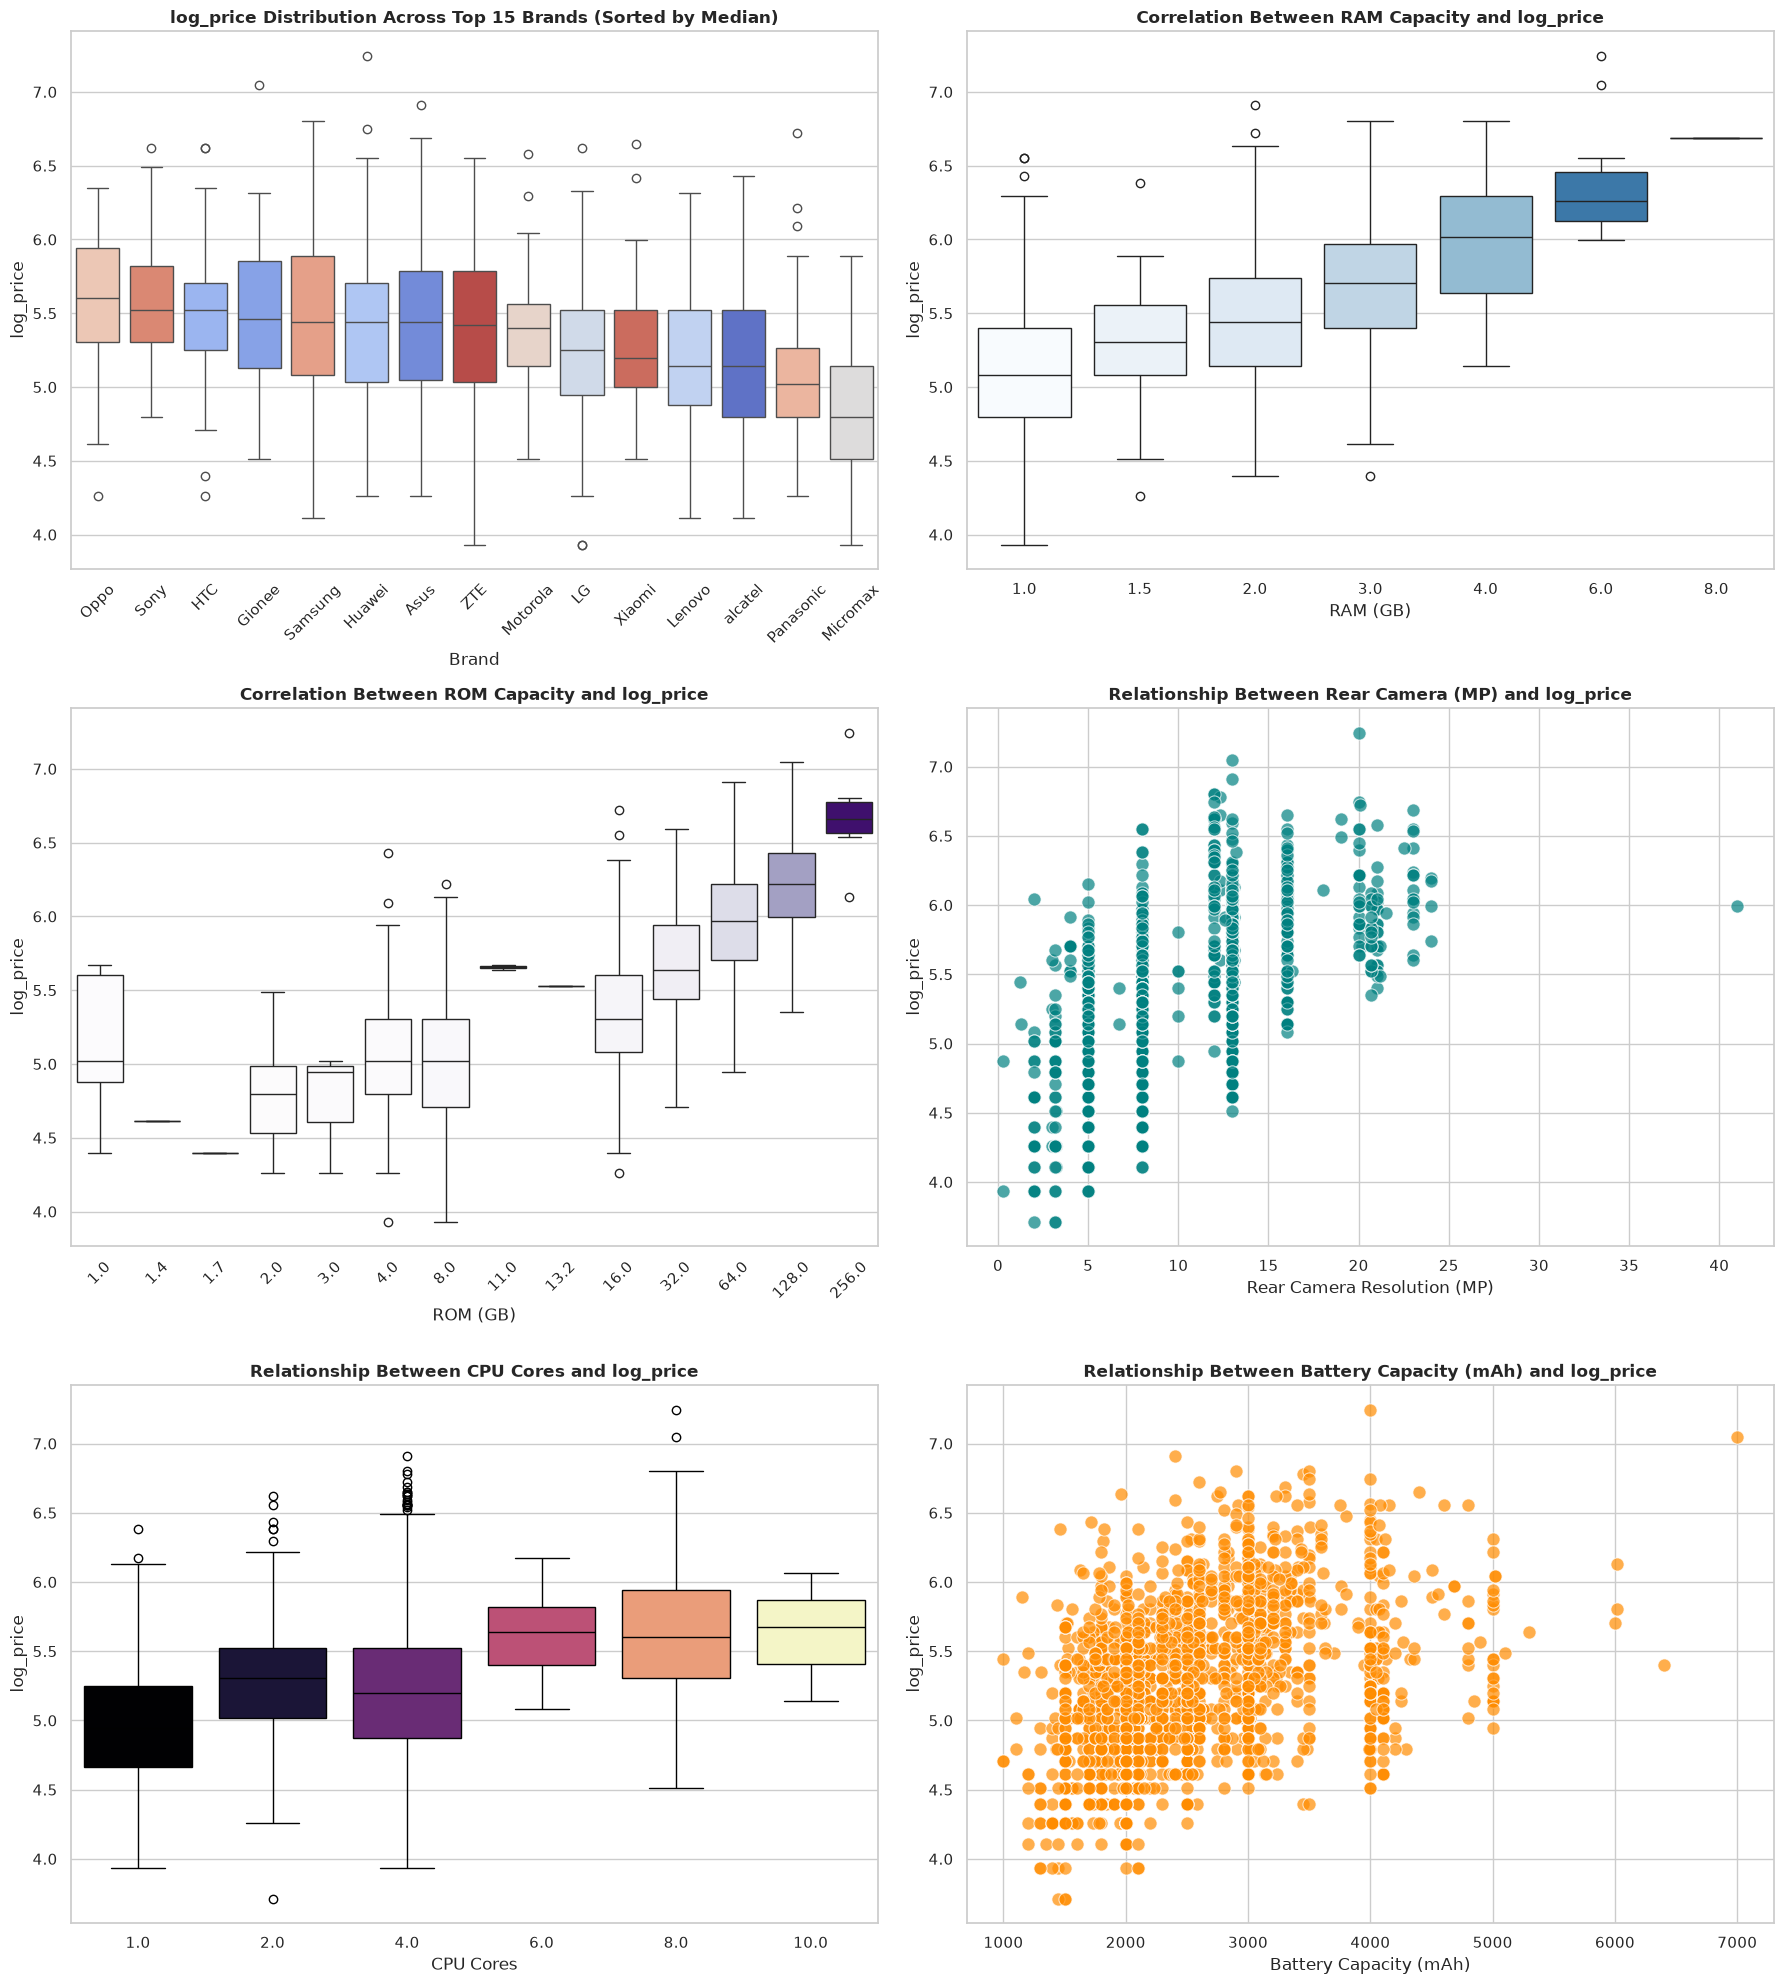

In [7]:
# Create a copy df_eda for visual exploration without modifying the main dataset
df_eda = df.copy()
df_eda['log_price'] = np.log1p(df_eda['Price (EUR)'])

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(18, 20))
axes = axes.flatten()

# 1. log_price by Brand (Top 15 brands with the most models, sorted by median price)
top_brands = df_eda['Brand'].value_counts().head(15).index
df_top_brands = df_eda[df_eda['Brand'].isin(top_brands)]
brand_order = df_top_brands.groupby('Brand')['log_price'].median().sort_values(ascending=False).index

sns.boxplot(data=df_top_brands, x='Brand', y='log_price', ax=axes[0], palette='coolwarm', order=brand_order, hue='Brand', legend=False)
axes[0].set_title('log_price Distribution Across Top 15 Brands (Sorted by Median)', fontsize=12, fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)
axes[0].set_xlabel('Brand')
axes[0].set_ylabel('log_price')

# 2. log_price by RAM (GB)
sns.boxplot(data=df_eda, x='RAM (GB)', y='log_price', ax=axes[1], palette='Blues', hue='RAM (GB)', legend=False)
axes[1].set_title('Correlation Between RAM Capacity and log_price', fontsize=12, fontweight='bold')
axes[1].set_xlabel('RAM (GB)')
axes[1].set_ylabel('log_price')

# 3. log_price by ROM (GB)
sns.boxplot(data=df_eda, x='ROM (GB)', y='log_price', ax=axes[2], palette='Purples', hue='ROM (GB)', legend=False)
axes[2].set_title('Correlation Between ROM Capacity and log_price', fontsize=12, fontweight='bold')
axes[2].tick_params(axis='x', rotation=45)
axes[2].set_xlabel('ROM (GB)')
axes[2].set_ylabel('log_price')

# 4. log_price by Rear Camera (MP)
sns.scatterplot(data=df_eda, x='Rear Camera (MP)', y='log_price', ax=axes[3], alpha=0.7, color='teal', s=90)
axes[3].set_title('Relationship Between Rear Camera (MP) and log_price', fontsize=12, fontweight='bold')
axes[3].set_xlabel('Rear Camera Resolution (MP)')
axes[3].set_ylabel('log_price')

# 5. log_price by CPU Cores
sns.boxplot(data=df_eda, x='CPU Cores', y='log_price', ax=axes[4], palette='magma', hue='CPU Cores', legend=False)
axes[4].set_title('Relationship Between CPU Cores and log_price', fontsize=12, fontweight='bold')
axes[4].set_xlabel('CPU Cores')
axes[4].set_ylabel('log_price')

# 6. log_price by Battery Capacity (mAh)
sns.scatterplot(data=df_eda, x='Battery Capacity (mAh)', y='log_price', ax=axes[5], alpha=0.7, color='darkorange', s=90)
axes[5].set_title('Relationship Between Battery Capacity (mAh) and log_price', fontsize=12, fontweight='bold')
axes[5].set_xlabel('Battery Capacity (mAh)')
axes[5].set_ylabel('log_price')

plt.tight_layout()
plt.show()

**Brand, RAM, ROM, CPU Cores, and Rear Camera:**  
We observe a clear positive relationship with `log_price`. Premium-positioned brands such as Apple, Sony, BlackBerry, and Samsung exhibit significantly higher median prices than budget-oriented brands like Micromax, Spice, and Celkon.  
Across standard storage tiers from 4GB -> 8GB -> 16GB -> 32GB -> 64GB -> 128GB -> 256GB, prices increase steadily with internal memory capacity.

### 5. Experimenting with and Exploring Derived Features (Feature Ideas)

**On Battery Capacity and Device Thickness:**  
When examining battery capacity in isolation, bulky budget phones with large batteries scatter the trend. Therefore, we experiment with the ratio **Battery Capacity / Thickness** (which reflects internal engineering optimization: packing a large battery into a slim body) and obtain a much clearer positive trend with `log_price`. At the same time, we detect an extreme outlier (`Battery/Thickness Ratio >= 800`).

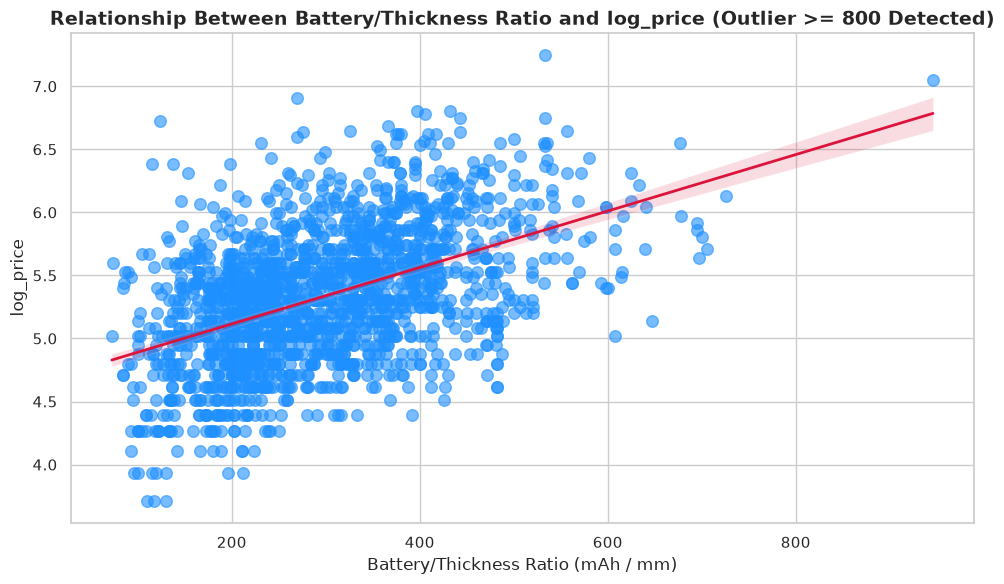

Number of outliers with Battery/Thickness Ratio >= 800: 1 row(s).


,Brand,Price (EUR),Battery Capacity (mAh),Thickness (mm),Battery/Thickness Ratio
371,Gionee,1150.0,7000.0,7.4,945.945946


In [8]:
# Compute experimental Battery/Thickness Ratio
df_eda['Battery/Thickness Ratio'] = df_eda['Battery Capacity (mAh)'] / df_eda['Thickness (mm)']

plt.figure(figsize=(10, 6))
sns.regplot(
    data=df_eda,
    x='Battery/Thickness Ratio',
    y='log_price',
    scatter_kws={'alpha': 0.6, 'color': 'dodgerblue', 's': 70},
    line_kws={'color': 'crimson', 'linewidth': 2}
)
plt.title('Relationship Between Battery/Thickness Ratio and log_price (Outlier >= 800 Detected)', fontsize=14, fontweight='bold')
plt.xlabel('Battery/Thickness Ratio (mAh / mm)', fontsize=12)
plt.ylabel('log_price', fontsize=12)
plt.tight_layout()
plt.show()

# Inspect the outlier with Battery/Thickness Ratio >= 800
pin_thick_outliers = df_eda[df_eda['Battery/Thickness Ratio'] >= 800]
print(f"Number of outliers with Battery/Thickness Ratio >= 800: {len(pin_thick_outliers)} row(s).")
if len(pin_thick_outliers) > 0:
    display(pin_thick_outliers[['Brand', 'Price (EUR)', 'Battery Capacity (mAh)', 'Thickness (mm)', 'Battery/Thickness Ratio']])

**On Display Panel Technology:**  
Currently there are several fine-grained display panel types, which can be grouped into two main tiers: high-end `OLED/AMOLED` panels and mainstream/budget `LCD` panels (IPS, TFT, PLS, Super LCD). We group them and inspect their price and resolution distributions.

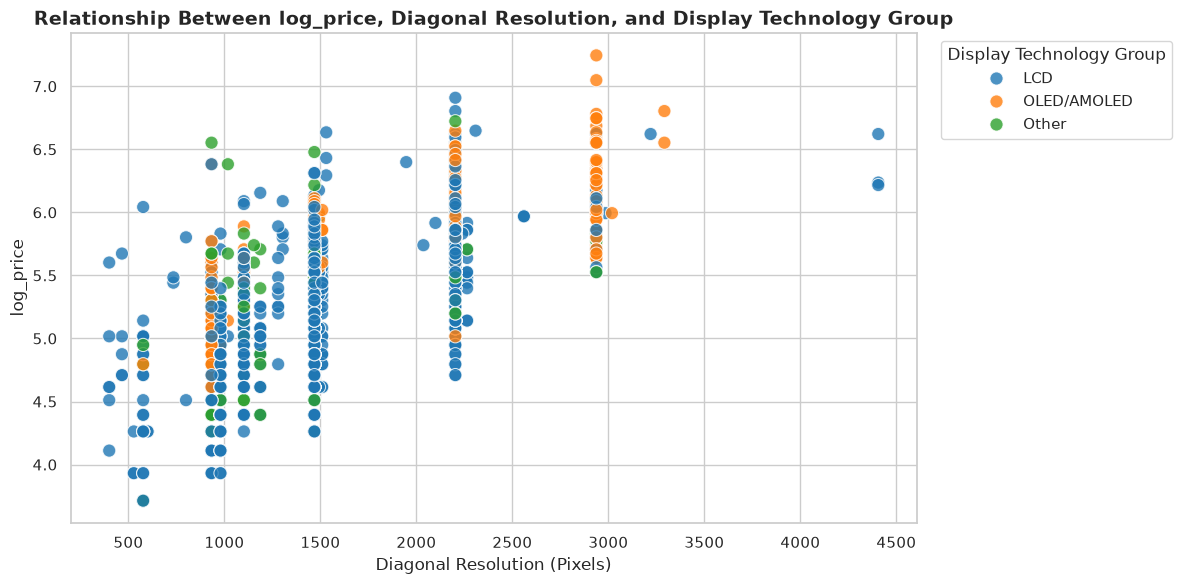

In [9]:
def group_display_panel_eda(panel):
    if pd.isna(panel):
        return 'Other'
    panel_lower = str(panel).lower()
    if 'oled' in panel_lower or 'amoled' in panel_lower:
        return 'OLED/AMOLED'
    elif any(x in panel_lower for x in ['lcd', 'tft', 'pls', 'ips']):
        return 'LCD'
    else:
        return 'Other'

df_eda['Display Technology Group'] = df_eda['Display Panel'].apply(group_display_panel_eda)

plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df_eda,
    x='Diagonal Resolution (Pixels)',
    y='log_price',
    hue='Display Technology Group',
    palette='tab10',
    alpha=0.8,
    s=90
)
plt.title('Relationship Between log_price, Diagonal Resolution, and Display Technology Group', fontsize=14, fontweight='bold')
plt.xlabel('Diagonal Resolution (Pixels)', fontsize=12)
plt.ylabel('log_price', fontsize=12)
plt.legend(title='Display Technology Group', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**On Display Panel Technology:**  
We can see a clear separation across price tiers and display resolutions. This confirms that display panel technology provides strong signal for downstream modeling.

**On Pixel Density (PPI) and Total CPU Clock Speed:**  
Instead of considering screen size alone, we combine diagonal resolution and screen size into pixel density (**PPI**), and combine core count and clock speed into **Total CPU Clock** to measure aggregate processing power:

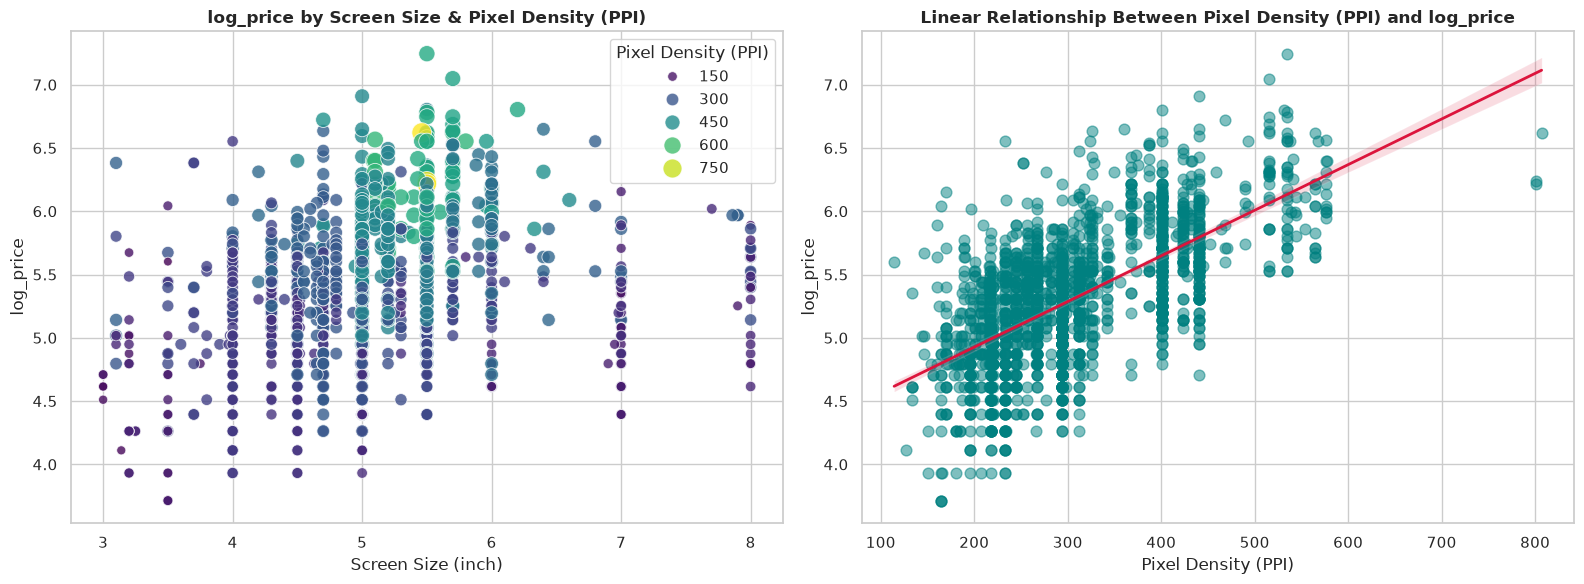

In [10]:
# Calculate standard PPI and Total CPU Clock
df_eda['Pixel Density (PPI)'] = df_eda['Diagonal Resolution (Pixels)'] / df_eda['Screen Size (inch)']
df_eda['Total CPU Clock'] = df_eda['CPU Cores'] * df_eda['CPU Clock Speed (GHz)']

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# 1. Screen Size vs log_price (Colored & sized by Pixel Density PPI)
sns.scatterplot(
    data=df_eda,
    x='Screen Size (inch)',
    y='log_price',
    hue='Pixel Density (PPI)',
    palette='viridis',
    size='Pixel Density (PPI)',
    sizes=(40, 200),
    alpha=0.8,
    ax=axes[0]
)
axes[0].set_title('log_price by Screen Size & Pixel Density (PPI)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Screen Size (inch)')
axes[0].set_ylabel('log_price')

# 2. Pixel Density (PPI) directly vs log_price
sns.regplot(
    data=df_eda,
    x='Pixel Density (PPI)',
    y='log_price',
    scatter_kws={'alpha': 0.5, 'color': 'teal', 's': 60},
    line_kws={'color': 'crimson', 'linewidth': 2},
    ax=axes[1]
)
axes[1].set_title('Linear Relationship Between Pixel Density (PPI) and log_price', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Pixel Density (PPI)')
axes[1].set_ylabel('log_price')

plt.tight_layout()
plt.show()

### 6. Analyzing Price Distributions by Fingerprint Sensor, Network Support, Battery Design, NFC, Release Year, and Chip Brand

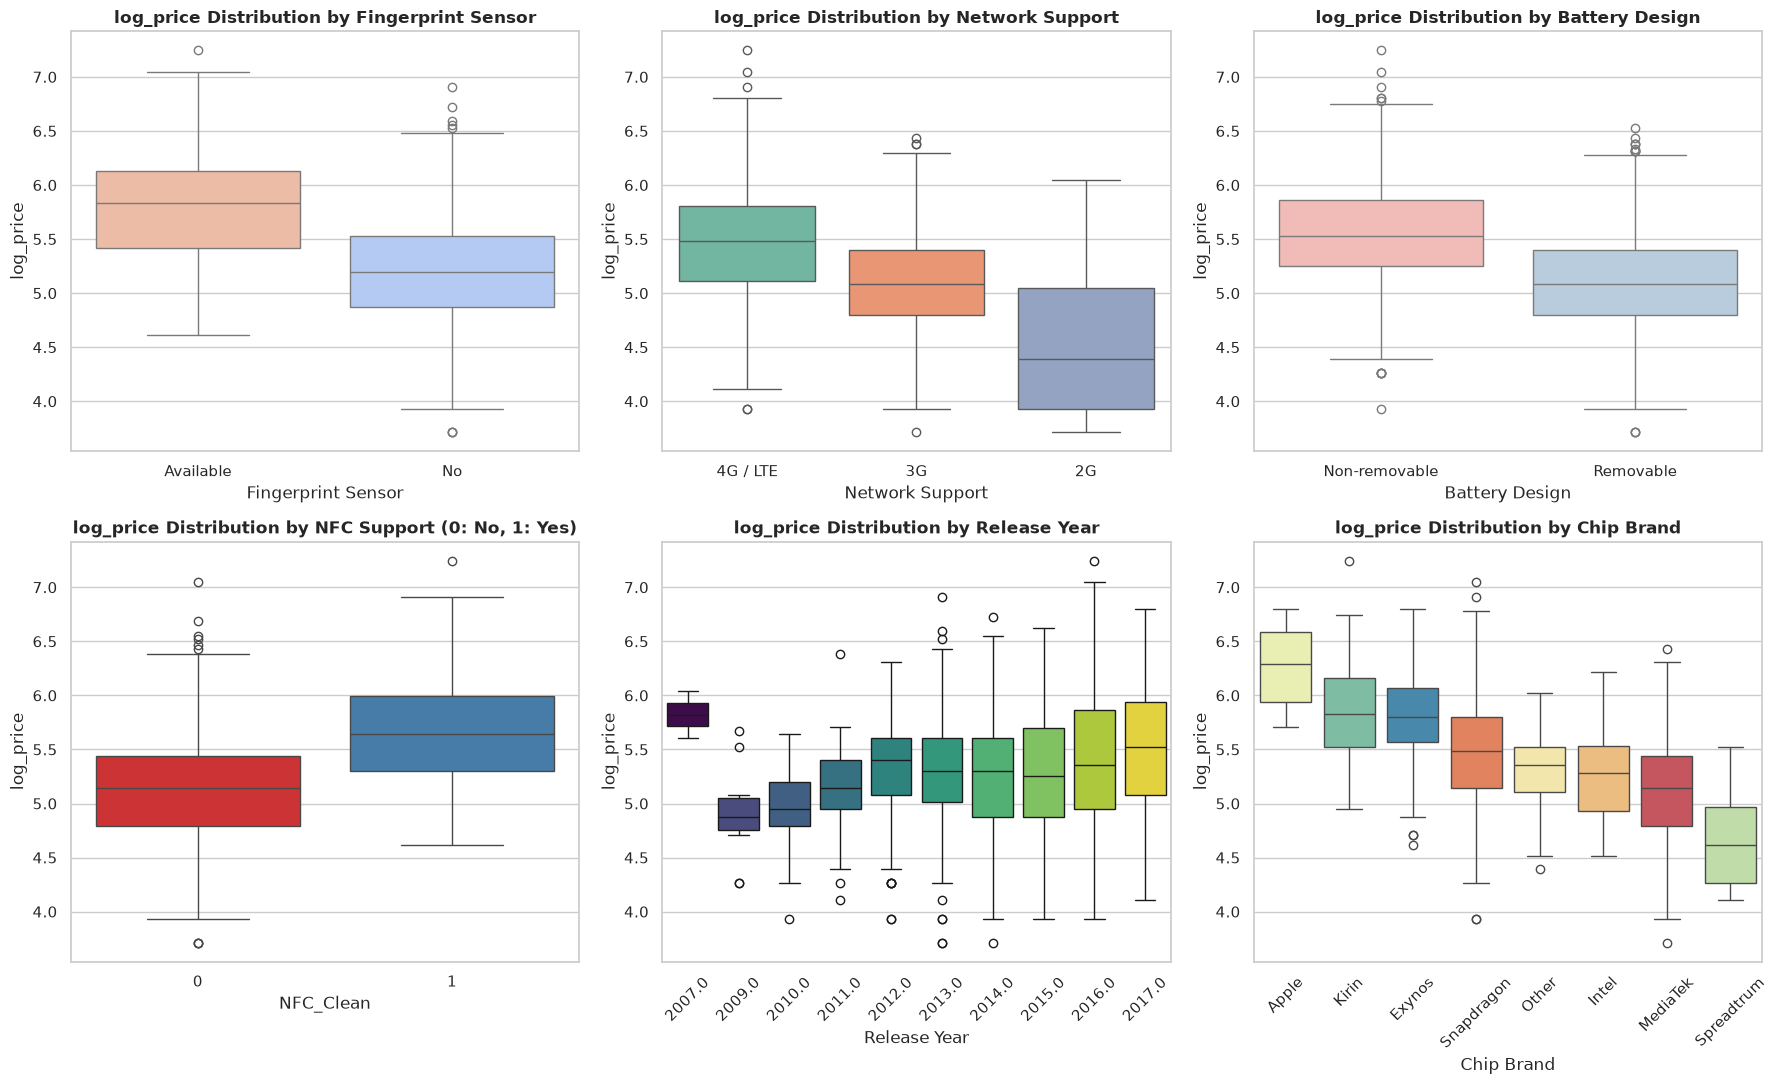

In [11]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 11))
axes = axes.flatten()

# 1. Price distribution by Fingerprint Sensor
fp_order = df_eda.groupby('Fingerprint Sensor')['log_price'].median().sort_values(ascending=False).index
sns.boxplot(
    data=df_eda,
    x='Fingerprint Sensor',
    y='log_price',
    ax=axes[0],
    palette='coolwarm',
    order=fp_order,
    hue='Fingerprint Sensor',
    legend=False
)
axes[0].set_title('log_price Distribution by Fingerprint Sensor', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Fingerprint Sensor')
axes[0].set_ylabel('log_price')

# 2. Price distribution by Network Support
network_order = df_eda.groupby('Network Support')['log_price'].median().sort_values(ascending=False).index
sns.boxplot(
    data=df_eda,
    x='Network Support',
    y='log_price',
    ax=axes[1],
    palette='Set2',
    order=network_order,
    hue='Network Support',
    legend=False
)
axes[1].set_title('log_price Distribution by Network Support', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Network Support')
axes[1].set_ylabel('log_price')

# 3. Price distribution by Battery Design
bat_order = df_eda.groupby('Battery Design')['log_price'].median().sort_values(ascending=False).index
sns.boxplot(
    data=df_eda,
    x='Battery Design',
    y='log_price',
    ax=axes[2],
    palette='Pastel1',
    order=bat_order,
    hue='Battery Design',
    legend=False
)
axes[2].set_title('log_price Distribution by Battery Design', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Battery Design')
axes[2].set_ylabel('log_price')

# 4. Price distribution by NFC_Clean
sns.boxplot(
    data=df_eda,
    x='NFC_Clean',
    y='log_price',
    ax=axes[3],
    palette='Set1',
    hue='NFC_Clean',
    legend=False
)
axes[3].set_title('log_price Distribution by NFC Support (0: No, 1: Yes)', fontsize=12, fontweight='bold')
axes[3].set_xlabel('NFC_Clean')
axes[3].set_ylabel('log_price')

# 5. Price distribution by Release Year
sns.boxplot(
    data=df_eda,
    x='Release Year',
    y='log_price',
    ax=axes[4],
    palette='viridis',
    hue='Release Year',
    legend=False
)
axes[4].set_title('log_price Distribution by Release Year', fontsize=12, fontweight='bold')
axes[4].tick_params(axis='x', rotation=45)
axes[4].set_xlabel('Release Year')
axes[4].set_ylabel('log_price')

# 6. Price distribution by Chip Brand
chip_order = df_eda.groupby('Chip Brand')['log_price'].median().sort_values(ascending=False).index
sns.boxplot(
    data=df_eda,
    x='Chip Brand',
    y='log_price',
    ax=axes[5],
    palette='Spectral',
    order=chip_order,
    hue='Chip Brand',
    legend=False
)
axes[5].set_title('log_price Distribution by Chip Brand', fontsize=12, fontweight='bold')
axes[5].tick_params(axis='x', rotation=45)
axes[5].set_xlabel('Chip Brand')
axes[5].set_ylabel('log_price')

plt.tight_layout()
plt.show()

We observe that fingerprint sensor availability, NFC connectivity, cellular network generation, battery design, and chipset brand all show strong differentiation across price tiers. Devices equipped with a fingerprint sensor, NFC (`NFC_Clean = 1`), 4G/LTE connectivity, and a non-removable unibody battery typically belong to the mid-range and high-end segments. Furthermore, combining `Release Year` with hardware specifications will help the model distinguish between older flagship phones and newer budget phones that share the same RAM/ROM capacity.

### 7. Surveying RAM and Battery Capacity Across Price Segments to Formulate the Imputation Strategy

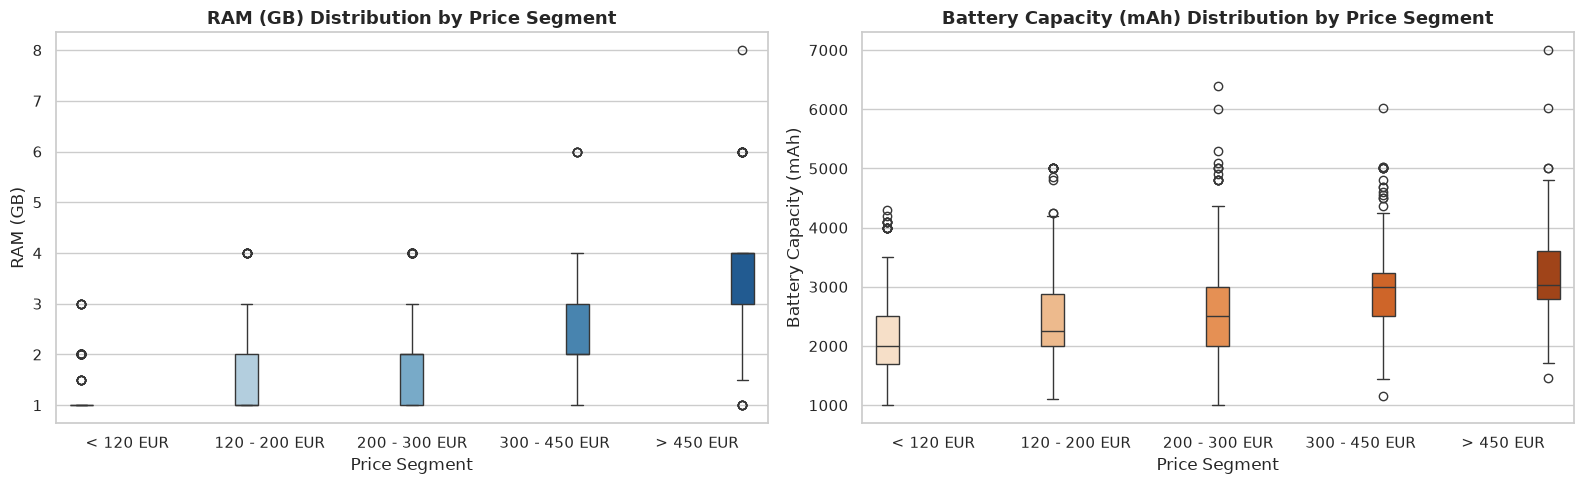

In [12]:
bins = [0, 120, 200, 300, 450, np.inf]
labels = ['< 120 EUR', '120 - 200 EUR', '200 - 300 EUR', '300 - 450 EUR', '> 450 EUR']
df_eda['Price Segment'] = pd.cut(df_eda['Price (EUR)'], bins=bins, labels=labels)

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 5))

sns.boxplot(data=df_eda, x='Price Segment', y='RAM (GB)', ax=axes[0], palette='Blues', hue='Price Segment', legend=False)
axes[0].set_title('RAM (GB) Distribution by Price Segment', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Price Segment')
axes[0].set_ylabel('RAM (GB)')

sns.boxplot(data=df_eda, x='Price Segment', y='Battery Capacity (mAh)', ax=axes[1], palette='Oranges', hue='Price Segment', legend=False)
axes[1].set_title('Battery Capacity (mAh) Distribution by Price Segment', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Price Segment')
axes[1].set_ylabel('Battery Capacity (mAh)')

plt.tight_layout()
plt.show()

### SUMMARY OF PREPROCESSING STRATEGY

1. **For RAM (GB), Screen Size, Screen-to-Body Ratio, Diagonal Resolution, Battery Capacity, Thickness, Weight, and CPU Clock Speed:**  
   Continuous distributions or distributions concentrated around the center (with `RAM (GB)` having a median around `1.5 GB`) $\rightarrow$ impute using the **Train Set Median** to remain robust against outliers.
2. **For ROM, Rear Camera, Front Camera, CPU Cores, and Release Year:**  
   Exhibit distinct discrete standard hardware tiers (such as ROM 8/16 GB, Camera 5/8 MP, 4-core CPU, Release Year 2014) $\rightarrow$ impute using the **Train Set Mode** (`NFC_Clean` is already 100% complete as binary `0/1`).
3. **For Display Panel and Chip Brand:**  
   Categorical variables $\rightarrow$ impute using the **Train Set Mode** based on the most frequent category in the training set.

## PART II: DATASET SPLITTING (TRAIN / VALIDATION / TEST SPLIT)
To ensure completely objective model evaluation and strictly prevent Data Leakage, we split the dataset right here:
- **Train Set (70%)**: Used to learn statistical imputation parameters, extract features, and train models.
- **Validation Set (15%)**: Used for hyperparameter tuning and iterative experimentation evaluation.
- **Test Set (15%)**: Used to evaluate final generalization performance on unseen data.

*(The temporary 'Price Segment' label is used solely for Stratified Splitting, ensuring an even distribution of price ranges across all 3 splits).*

In [13]:
# 1. Create price segment labels strictly for Stratified Splitting
bins = [0, 120, 200, 300, 450, np.inf]
labels = ['< 120 EUR', '120 - 200 EUR', '200 - 300 EUR', '300 - 450 EUR', '> 450 EUR']
stratify_labels = pd.cut(df['Price (EUR)'], bins=bins, labels=labels)

# 2. Split into Train (70%) and Temp (30%)
df_train, df_temp = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=stratify_labels
)

# 3. Split Temp into Validation (15%) and Test (15%)
stratify_temp = stratify_labels.loc[df_temp.index]
df_val, df_test = train_test_split(
    df_temp,
    test_size=0.50,
    random_state=42,
    stratify=stratify_temp
)

# Create independent copies and reset indices
df_train = df_train.copy().reset_index(drop=True)
df_val = df_val.copy().reset_index(drop=True)
df_test = df_test.copy().reset_index(drop=True)

print(f"Training Set size (Train Set):        {df_train.shape[0]} rows (70%)")
print(f"Validation Set size (Val Set):        {df_val.shape[0]} rows (15%)")
print(f"Final Evaluation Set size (Test Set): {df_test.shape[0]} rows (15%)")

Training Set size (Train Set):        1337 rows (70%)
Validation Set size (Val Set):        286 rows (15%)
Final Evaluation Set size (Test Set): 287 rows (15%)


## PART III: MINIMAL PREPROCESSING FOR BASELINE MODELS

Following a rigorous machine learning workflow:
- Right after splitting the dataset, we **do not yet introduce complex engineered features** (such as Battery/Thickness Ratio, PPI, Total CPU Clock, or display panel grouping) into the baseline feature table.
- At this stage, we **only perform Minimal Preprocessing** just enough for machine learning models to ingest the data:
  1. **Missing Value Imputation:** Impute directly using the **Median / Mode** learned strictly from the Train Set for each feature group.
  2. **Categorical Encoding:** Apply basic One-Hot Encoding to the original categorical columns (`Brand`, `Display Panel`, `Battery Design`, `Network Support`, `Fingerprint Sensor`, `Chip Brand`).
  3. **Target Variable ($y$):** Keep the original `Price (EUR)` scale to measure prediction errors directly in EUR.

Core Objective: **Build Baseline Models immediately as a reference benchmark** to quantitatively evaluate subsequent feature engineering and tuning iterations!

In [14]:
# 1. Define lists of original numeric and categorical columns
numeric_cols = [
    'RAM (GB)', 'ROM (GB)', 'Screen Size (inch)',
    'Screen-to-Body Ratio (%)', 'Rear Camera (MP)', 'Front Camera (MP)',
    'Battery Capacity (mAh)', 'Thickness (mm)', 'Weight (g)',
    'CPU Cores', 'CPU Clock Speed (GHz)',
    'Release Year', 'NFC_Clean', 'Diagonal Resolution (Pixels)'
]

discrete_mode_cols = [
    'ROM (GB)', 'Rear Camera (MP)', 'Front Camera (MP)',
    'CPU Cores', 'Release Year', 'NFC_Clean'
]

cat_cols = [
    'Brand', 'Display Panel', 'Battery Design',
    'Network Support', 'Fingerprint Sensor', 'Chip Brand'
]

# 2. Learn imputation statistics STRICTLY FROM df_train
train_stats = {}
for col in numeric_cols:
    if col in discrete_mode_cols:
        train_stats[col] = df_train[col].mode()[0]
    else:
        train_stats[col] = df_train[col].median()

for col in cat_cols:
    train_stats[col] = df_train[col].mode()[0]

print("--- MINIMAL STATISTICS LEARNED FROM TRAIN SET ---")
for k, v in list(train_stats.items())[:10]:
    print(f" - {k}: {v}")

chip_order = ['Apple', 'Exynos', 'Intel', 'Other', 'Kirin', 'MediaTek', 'Snapdragon', 'Spreadtrum']

# 3. Minimal preprocessing function (Fit on Train -> Transform on Val/Test)
def minimal_preprocess(df_input, stats, train_dummy_cols=None):
    data = df_input.copy()
    
    # Fill missing numeric values with Train Median/Mode
    for col in numeric_cols:
        data[col] = data[col].fillna(stats[col])
        
    # Fill missing categorical values with Train Mode
    for col in cat_cols:
        data[col] = data[col].fillna(stats[col])
        
    data['Chip Brand'] = pd.Categorical(data['Chip Brand'], categories=chip_order)
    
    # Basic One-Hot Encoding for original categorical columns
    data_encoded = pd.get_dummies(data, columns=cat_cols, drop_first=True)
    
    # Align column structure with the Train Set
    if train_dummy_cols is not None:
        data_encoded = data_encoded.reindex(columns=train_dummy_cols, fill_value=0)
        
    return data_encoded

# Apply to Train Set first to establish the reference column list
df_train_proc = minimal_preprocess(df_train, train_stats)
train_encoded_cols = df_train_proc.columns.tolist()

# Apply to Validation and Test Sets
df_val_proc = minimal_preprocess(df_val, train_stats, train_dummy_cols=train_encoded_cols)
df_test_proc = minimal_preprocess(df_test, train_stats, train_dummy_cols=train_encoded_cols)

print(f"\nMinimal preprocessing completed successfully:")
print(f"Train: {df_train_proc.shape}, Remaining missing values: {df_train_proc.isnull().sum().sum()}")
print(f"Val:   {df_val_proc.shape}, Remaining missing values: {df_val_proc.isnull().sum().sum()}")
print(f"Test:  {df_test_proc.shape}, Remaining missing values: {df_test_proc.isnull().sum().sum()}")

--- MINIMAL STATISTICS LEARNED FROM TRAIN SET ---
 - RAM (GB): 1.75
 - ROM (GB): 16.0
 - Screen Size (inch): 5.0
 - Screen-to-Body Ratio (%): 67.5
 - Rear Camera (MP): 8.0
 - Front Camera (MP): 5.0
 - Battery Capacity (mAh): 2470.0
 - Thickness (mm): 8.9
 - Weight (g): 149.0
 - CPU Cores: 4.0

Minimal preprocessing completed successfully:
Train: (1337, 91), Remaining missing values: 0
Val:   (286, 91), Remaining missing values: 0
Test:  (287, 91), Remaining missing values: 0


### Separate Feature Matrix ($X$) and Target Vector ($y$)
The target variable $y$ is kept in its original `Price (EUR)` scale so that Mean Absolute Error (MAE) can be directly interpreted in real currency units.

In [15]:
target_col = 'Price (EUR)'

X_train = df_train_proc.drop(columns=[target_col])
y_train = df_train_proc[target_col]

X_val = df_val_proc.drop(columns=[target_col])
y_val = df_val_proc[target_col]

X_test = df_test_proc.drop(columns=[target_col])
y_test = df_test_proc[target_col]

print("Data structures ready for Baseline Models:")
print(f" - X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f" - X_val:   {X_val.shape}, y_val:   {y_val.shape}")
print(f" - X_test:  {X_test.shape}, y_test:  {y_test.shape}")

Data structures ready for Baseline Models:
 - X_train: (1337, 90), y_train: (1337,)
 - X_val:   (286, 90), y_val:   (286,)
 - X_test:  (287, 90), y_test:  (287,)


## PART IV: BUILDING AND EVALUATING BASELINE MODELS (Step 6)

We train 3 baseline models:
1. **Linear Regression**: Basic linear model to test linear relationships between hardware specifications and price.
2. **Random Forest Regressor (Default)**: Multivariate decision tree ensemble that requires no feature scaling and automatically learns complex non-linear interactions.
3. **XGBoost Regressor (Default)**: Powerful Gradient Boosting algorithm on tabular data.

We evaluate performance on the **Validation Set** using 3 metrics:
- **MAE (Mean Absolute Error):** Average magnitude of absolute errors (in EUR).
- **RMSE (Root Mean Squared Error):** Square root of mean squared error (heavily penalizes large errors).
- **R² Score:** Proportion of variance explained by the model (closer to 1 is better).

In [16]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from xgboost import XGBRegressor

# Initialize baseline models
baseline_models = {
    'Linear Regression': LinearRegression(),
    'Random Forest (Default)': RandomForestRegressor(random_state=42),
    'XGBoost (Default)': XGBRegressor(random_state=42),
}

baseline_results = []

# Train and evaluate on the Validation Set
for name, model in baseline_models.items():
    # Fit on Train
    model.fit(X_train, y_train)

    # Predict on Validation
    y_pred_val = model.predict(X_val)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_val, y_pred_val)
    rmse = root_mean_squared_error(y_val, y_pred_val)
    r2 = r2_score(y_val, y_pred_val)

    baseline_results.append({
        'Model': name,
        'Val MAE (EUR)': f'{mae:,.2f} €',
        'Val RMSE (EUR)': f'{rmse:,.2f} €',
        'Val R² Score': round(r2, 4),
    })

# Display summary table of Baseline results
df_baseline_results = pd.DataFrame(baseline_results)
print('=== BASELINE MODEL RESULTS TABLE (REFERENCE BENCHMARK) ===')
display(df_baseline_results)

=== BASELINE MODEL RESULTS TABLE (REFERENCE BENCHMARK) ===


,Model,Val MAE (EUR),Val RMSE (EUR),Val R² Score
0,Linear Regression,58.20 €,86.23 €,0.6154
1,Random Forest (Default),52.32 €,75.88 €,0.7022
2,XGBoost (Default),51.46 €,77.98 €,0.6855


### Baseline Results Analysis and Next Improvement Directions

> **Baseline Results Commentary:**
> - **Random Forest (Default)** achieves the best overall baseline performance across RMSE and $R^2$ with **MAE $\approx$ 52.32 €**, **RMSE $\approx$ 75.88 €**, and **$R^2 \approx$ 0.7022**, demonstrating a strong ability to capture non-linear relationships between hardware specs, release year, NFC, and price even without hyperparameter tuning.
> - **XGBoost (Default)** ranks second in $R^2$ (and best in MAE) with **MAE $\approx$ 51.46 €**, **RMSE $\approx$ 77.98 €**, and **$R^2 \approx$ 0.6855**. Default boosting models are often sensitive to hyperparameters and unrefined feature spaces, leading to mild overfitting on the training set.
> - **Linear Regression** yields the lowest performance (**MAE $\approx$ 58.20 €**, **RMSE $\approx$ 86.23 €**, **$R^2 \approx$ 0.6154**), reflecting that smartphone pricing depends heavily on non-linear hardware interactions across release eras.

---

### 📌 Next Directions for Improvement

1. **Hyperparameter Tuning:**
   - Tune **XGBoost** using `RandomizedSearchCV` (reducing `max_depth`, tuning `learning_rate`, `subsample`, `n_estimators`) to control overfitting and improve $R^2$.
   - Tune `n_estimators`, `max_depth`, and `min_samples_split` for **Random Forest** to further reduce RMSE.

2. **Outlier Handling & Target Transformation:**
   - The gap between MAE and RMSE across all 3 models indicates that high-end devices cause larger prediction errors. Applying a `log-transform` to the target variable and regularizing linear models will help mitigate this effect.

3. **Feature Engineering:**
   - Incorporate the interaction and domain features explored during EDA, such as `Pixel Density (PPI)`, `Battery/Thickness Ratio`, `Total CPU Clock`, time-relative Moore's Law features, and `Smoothed Target Encoding` in the subsequent modeling notebooks.

In [17]:
pd.set_option('display.max_columns', None)
display(X_train.head())

,RAM (GB),ROM (GB),Screen Size (inch),Screen-to-Body Ratio (%),Rear Camera (MP),Front Camera (MP),Battery Capacity (mAh),Thickness (mm),Weight (g),CPU Cores,CPU Clock Speed (GHz),Release Year,NFC_Clean,Diagonal Resolution (Pixels),Brand_Allview,Brand_Amazon,Brand_Apple,Brand_Archos,Brand_Asus,Brand_BLU,Brand_BQ,Brand_BenQ,Brand_BlackBerry,Brand_Casio,Brand_Cat,Brand_Celkon,Brand_Coolpad,Brand_Dell,Brand_Gigabyte,Brand_Gionee,Brand_Google,Brand_HP,Brand_HTC,Brand_Huawei,Brand_Jolla,Brand_Karbonn,Brand_Kyocera,Brand_LG,Brand_Lava,Brand_LeEco,Brand_Lenovo,Brand_Meizu,Brand_Micromax,Brand_Microsoft,Brand_Motorola,Brand_NEC,Brand_Nokia,Brand_Nvidia,Brand_OnePlus,Brand_Oppo,Brand_Orange,Brand_Panasonic,Brand_Pantech,Brand_Philips,Brand_Prestigio,Brand_QMobile,Brand_Samsung,Brand_Sharp,Brand_Sonim,Brand_Sony,Brand_Spice,Brand_T-Mobile,Brand_Toshiba,Brand_Vodafone,Brand_Wiko,Brand_XOLO,Brand_Xiaomi,Brand_YU,Brand_Yota,Brand_ZTE,Brand_alcatel,Brand_verykool,Brand_vivo,Display Panel_IPS LCD,Display Panel_OLED,Display Panel_PLS LCD,Display Panel_Super AMOLED,Display Panel_Super LCD,Display Panel_TFT LCD,Battery Design_Removable,Network Support_3G,Network Support_4G / LTE,Fingerprint Sensor_No,Chip Brand_Exynos,Chip Brand_Intel,Chip Brand_Other,Chip Brand_Kirin,Chip Brand_MediaTek,Chip Brand_Snapdragon,Chip Brand_Spreadtrum
0,3.0,64.0,6.0,73.5,24.0,8.0,3500.0,9.6,210.0,8.0,2.00,2015.0,1,2937.209560,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,True,False,False
1,2.0,16.0,5.0,67.7,13.0,5.0,2200.0,8.0,133.0,4.0,1.25,2017.0,0,1468.604780,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,True,False
2,2.0,32.0,8.0,70.8,5.0,1.2,2470.0,7.5,299.0,4.0,2.30,2014.0,1,2264.155472,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,True,False,True,False,False,False,False,False
3,2.0,32.0,5.0,69.2,13.0,2.0,2600.0,9.1,147.0,4.0,2.30,2013.0,1,2202.907170,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False,True,True,False,False,False,False,False,True,False
4,3.0,16.0,5.0,68.8,13.0,5.0,4100.0,7.9,145.0,8.0,1.40,2016.0,0,1468.604780,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,True,False,False


In [18]:
# ==============================================================================
# 1. CLEAN MISSING VALUE IMPUTATION (FIT ON TRAIN -> TRANSFORM ALL 3 SPLITS)
# ==============================================================================

numeric_cols = [
    'RAM (GB)', 'ROM (GB)', 'Screen Size (inch)',
    'Screen-to-Body Ratio (%)', 'Rear Camera (MP)', 'Front Camera (MP)',
    'Battery Capacity (mAh)', 'Thickness (mm)', 'Weight (g)',
    'CPU Cores', 'CPU Clock Speed (GHz)',
    'Release Year', 'NFC_Clean', 'Diagonal Resolution (Pixels)'
]
discrete_mode_cols = [
    'ROM (GB)', 'Rear Camera (MP)', 'Front Camera (MP)',
    'CPU Cores', 'Release Year', 'NFC_Clean'
]
cat_cols = [
    'Brand', 'Display Panel', 'Battery Design',
    'Network Support', 'Fingerprint Sensor', 'Chip Brand'
]

# Learn statistics STRICTLY FROM the Train Set
stats = {}
for col in numeric_cols:
    stats[col] = df_train[col].mode()[0] if col in discrete_mode_cols else df_train[col].median()
stats.update({col: df_train[col].mode()[0] for col in cat_cols})

# Impute missing values while KEEPING THE 21 ORIGINAL COLUMNS (BEFORE ONE-HOT ENCODING)
def fill_missing_keep_original(df_input, stats):
    data = df_input.copy()
    
    # Fill numeric columns using Median/Mode learned from Train
    for col in numeric_cols:
        data[col] = data[col].fillna(stats[col])
        
    # Fill categorical columns using Mode learned from Train
    for col in cat_cols:
        data[col] = data[col].fillna(stats[col])
        
    return data

# Impute all 3 splits cleanly
df_train_clean = fill_missing_keep_original(df_train, stats)
df_val_clean   = fill_missing_keep_original(df_val, stats)
df_test_clean  = fill_missing_keep_original(df_test, stats)

print("Check remaining NaN counts:")
print(f"- Train: {df_train_clean.isnull().sum().sum()} NaN")
print(f"- Val:   {df_val_clean.isnull().sum().sum()} NaN")
print(f"- Test:  {df_test_clean.isnull().sum().sum()} NaN")

# ==============================================================================
# 2. EXPORT TO CSV FILES FOR DOWNSTREAM MODELING NOTEBOOKS
# ==============================================================================
os.makedirs('data', exist_ok=True)
df_train_clean.to_csv('data/smartphones_train_clean.csv', index=False, encoding='utf-8-sig')
df_val_clean.to_csv('data/smartphones_val_clean.csv', index=False, encoding='utf-8-sig')
df_test_clean.to_csv('data/smartphones_test_clean.csv', index=False, encoding='utf-8-sig')

print("\nExported 3 imputed CSV files (retaining the 21 original columns):")
print("1. data/smartphones_train_clean.csv")
print("2. data/smartphones_val_clean.csv")
print("3. data/smartphones_test_clean.csv")

Check remaining NaN counts:
- Train: 0 NaN
- Val:   0 NaN
- Test:  0 NaN

Exported 3 imputed CSV files (retaining the 21 original columns):
1. data/smartphones_train_clean.csv
2. data/smartphones_val_clean.csv
3. data/smartphones_test_clean.csv
